# Module 5: Solving Black-Scholes and Fixed Income Models, Tested on Real Data

*By Héctor Ornelas*

Module 4 derived the Black-Scholes equation quickly and tested the hedge with real data. This module
goes back to the details. First it fixes a weak point of the quick derivation, then it actually solves
the equation by turning it into the diffusion equation, and finally it carries the same method to
bonds, where the variable that drives prices, the interest rate, cannot be bought or sold. As before, I
take the nine topics of the course in the same order and test each one with real data.

The rules are the same as in Module 1: same topics as the course, real data from a Mexican point of
view, and every formula written by hand. This module adds the US Treasury curve (1, 2, 5 and 10 years)
and the Mexican 10-year bond yield, both from FRED.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import erf, exp, log, pi, sqrt

# fix the seed so every run gives exactly the same numbers
np.random.seed(37)

# one common style for all the plots: size, a light grid, and font size
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})

def Phi(x):
    return 0.5 * (1 + erf(x / sqrt(2)))

def bs_call(S, K, T, r, sig):
    # Black-Scholes call price and delta, written by hand
    d1 = (log(S / K) + (r + sig**2 / 2) * T) / (sig * sqrt(T))
    d2 = d1 - sig * sqrt(T)
    return S * Phi(d1) - K * exp(-r * T) * Phi(d2), Phi(d1)

prices = pd.read_csv("data/prices.csv", index_col=0, parse_dates=True)
rates = pd.read_csv("data/rates.csv", index_col=0, parse_dates=True)

# SPY, VIX and the US 3-month rate on SPY trading days
spy = pd.concat([prices[["SPY", "VIX"]], rates["US3M"]], axis=1, sort=True).ffill()
spy = spy[spy.index.isin(prices["SPY"].dropna().index)].dropna()

# today's inputs for one at-the-money SPY call that expires in one month
S0, sig0, r0 = spy["SPY"].iloc[-1], spy["VIX"].iloc[-1] / 100, spy["US3M"].iloc[-1] / 100
T0 = 21 / 252
print(f"last day {spy.index[-1].date()}:  SPY {S0:.2f}   VIX {sig0:.1%}   US 3-month rate {r0:.2%}")

last day 2026-10-14:  SPY 769.60   VIX 16.9%   US 3-month rate 4.09%


## 1. The flaw: delta is not constant

The quick derivation of Black-Scholes wrote the change of the hedged portfolio as
$d\Pi = dV - \Delta\,dS$, which treats $\Delta$ as a constant. But the same derivation concludes that
$\Delta = \partial V/\partial S$, and $V$ depends on both $S$ and $t$, so $\Delta$ changes all the time.

**Exercise 1. How much does delta move?** For every month since 2005, I take a one-month at-the-money
SPY call, priced with the VIX, and I compute its delta every day until it expires.

261 months
delta at the start of each month: about 0.5 (at the money)
range of delta inside a month  : median 0.52   largest 0.93 (2020-02)
average daily change of delta  : 0.060


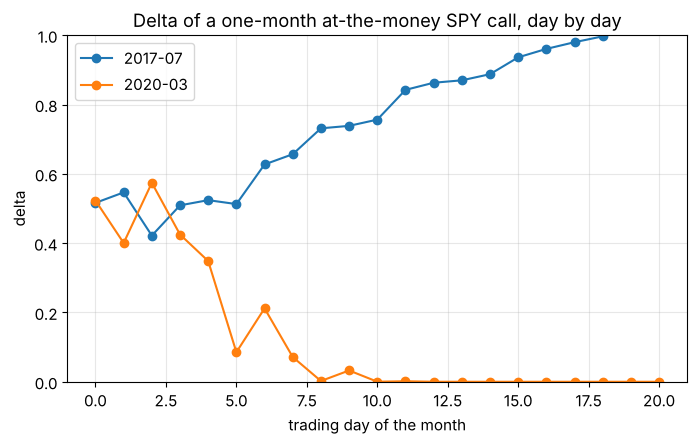

In [2]:
# one-month at-the-money calls, one per month, as in Module 4: how much does delta move inside each month?
rows, paths = [], {}
for per, g in spy.groupby(spy.index.to_period("M")):
    if len(g) < 18:
        continue
    S, sig, rate = g["SPY"].values, g["VIX"].iloc[0] / 100, g["US3M"].iloc[0] / 100
    n, K = len(g) - 1, S[0]
    d = np.array([bs_call(S[i], K, (n - i) / 252, rate, sig)[1] for i in range(n)])
    paths[str(per)] = d
    rows.append([per, d.max() - d.min(), np.mean(np.abs(np.diff(d)))])
dm = pd.DataFrame(rows, columns=["month", "range", "avg daily change"]).set_index("month")

print(f"{len(dm)} months")
print(f"delta at the start of each month: about 0.5 (at the money)")
print(f"range of delta inside a month  : median {dm['range'].median():.2f}   largest {dm['range'].max():.2f} ({dm['range'].idxmax()})")
print(f"average daily change of delta  : {dm['avg daily change'].mean():.3f}")

for m in ["2017-07", "2020-03"]:
    plt.plot(paths[m], "o-", label=m)
plt.title("Delta of a one-month at-the-money SPY call, day by day")
plt.xlabel("trading day of the month"); plt.ylabel("delta"); plt.ylim(0, 1); plt.legend(); plt.show()

Delta is far from constant. It starts around 0.5 and, in a typical month, moves over a range of 0.52,
so by the end of the month the hedge can need almost twice or almost none of the shares it started
with. On average it changes by 0.06 every day. The plot compares a calm month, July 2017, with March
2020: in the first one delta goes up slowly as the SPY rises, and in the second one it falls toward
zero in a few days. So the quick derivation was missing something, and the next section fixes it.

## 2. The repair: a self-financing portfolio

The fix is to include a **cash account** and require the strategy to be **self-financing**: it starts
with zero money, every share bought is paid from the cash account, every share sold puts money back,
and no money comes in or goes out from outside. With this condition, the terms that were dropped cancel
out, and the same Black-Scholes equation appears, this time correctly.

**Exercise 2. Self-financing against a static hedge.** With the same monthly calls, I compare two
hedges: a self-financing one that rebalances every day, with the cash account growing at the US
3-month rate, and a static one that buys the first day's delta and never trades again.

In [3]:
# same calls: rebalance every day (self-financing), or keep the delta of the first day all month
rows = []
for per, g in spy.groupby(spy.index.to_period("M")):
    if len(g) < 18:
        continue
    S, sig, rate = g["SPY"].values, g["VIX"].iloc[0] / 100, g["US3M"].iloc[0] / 100
    n, K = len(g) - 1, S[0]
    price, d0 = bs_call(S[0], K, n / 252, rate, sig)
    payoff = max(S[-1] - K, 0)

    # self-financing: start with the premium, every share bought or sold is paid from the cash account
    cash, delta, injected = price - d0 * S[0], d0, 0.0
    for i in range(1, n):
        cash *= exp(rate / 252)
        new_delta = bs_call(S[i], K, (n - i) / 252, rate, sig)[1]
        cash -= (new_delta - delta) * S[i]        # no money comes in or goes out, only moves between stock and cash
        delta = new_delta
    cash *= exp(rate / 252)
    dynamic = cash + delta * S[-1] - payoff

    # static: buy d0 shares on day one and never trade again
    static = (price - d0 * S[0]) * exp(rate * n / 252) + d0 * S[-1] - payoff
    rows.append([dynamic / S[0], static / S[0]])
h = pd.DataFrame(rows, columns=["self-financing", "static delta"])

print(f"{'':<16}{'mean P&L':>10}{'std':>8}{'worst':>9}")
for c in h.columns:
    print(f"{c:<16}{h[c].mean():>10.3%}{h[c].std():>8.3%}{h[c].min():>9.2%}")

                  mean P&L     std    worst
self-financing      0.399%  0.627%   -2.70%
static delta        0.491%  1.188%   -4.58%


The self-financing hedge has a standard deviation of 0.63% of the SPY per month, and the static hedge
1.19%, almost twice. Its worst month is also much better, $-2.70\%$ against $-4.58\%$. So the
rebalancing, paid only with money from inside the portfolio, is what makes the hedge work. The static
hedge had a slightly higher average result (0.49% against 0.40%), but with almost twice the risk, and
the goal of a hedge is to remove risk, not to earn more. This is the correct version of the strategy
used in Module 4, and the same caveat applies: there are no transaction costs, so rebalancing every day
is free here and would cost something in practice.

## 3. The diffusion equation and its fundamental solution

The route to solving Black-Scholes is to turn it into the **diffusion equation**

$$\frac{\partial p}{\partial t} = \frac12\frac{\partial^2 p}{\partial z^2},$$

whose most important solution is the Gaussian kernel

$$p_0(z,t) = \frac{1}{\sqrt{2\pi t}}\,e^{-z^2/(2t)}.$$

It starts as a spike at zero and spreads out: its width grows like $\sqrt{t}$ and its peak falls like
$1/\sqrt{t}$. It is the density of a Brownian motion at time $t$.

**Exercise 3. The IPC spreading out.** I take the changes in the log IPC over 1, 21, 63 and 252 days,
and compare their distribution with the kernel $p_0$ with width $\sigma\sqrt{t}$.

 days  real peak  kernel peak  real std  sigma sqrt(t)
    1      46.12        34.32    0.0116         0.0116
   21       9.57         7.49    0.0517         0.0533
   63       5.92         4.32    0.0855         0.0923
  252       3.51         2.16    0.1790         0.1845


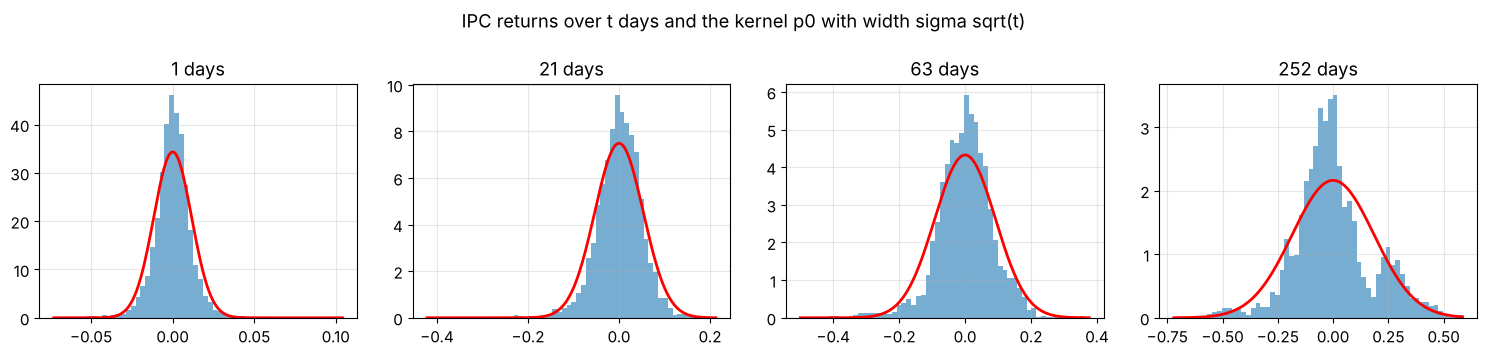

In [4]:
r_ipc = np.log(prices["IPC"].dropna())
sig_d = r_ipc.diff().std()

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6), sharey=False)
print(f"{'days':>5}{'real peak':>11}{'kernel peak':>13}{'real std':>10}{'sigma sqrt(t)':>15}")
for a, h in zip(ax, [1, 21, 63, 252]):
    x = (r_ipc.values[h:] - r_ipc.values[:-h])
    x = x - x.mean()
    width = sig_d * sqrt(h)
    hist, edges = np.histogram(x, bins=60, density=True)
    peak_kernel = 1 / (width * sqrt(2 * pi))        # height of p0(0, t)
    print(f"{h:>5}{hist.max():>11.2f}{peak_kernel:>13.2f}{x.std():>10.4f}{width:>15.4f}")
    grid = np.linspace(edges[0], edges[-1], 300)
    a.bar(edges[:-1], hist, width=np.diff(edges), align="edge", alpha=0.6)
    a.plot(grid, np.exp(-grid**2 / (2 * width**2)) / (width * sqrt(2 * pi)), color="red", lw=2)
    a.set_title(f"{h} days")
plt.suptitle("IPC returns over t days and the kernel p0 with width sigma sqrt(t)"); plt.tight_layout(); plt.show()

The width follows the kernel well: the real standard deviation goes from 0.0116 at one day to 0.179 at
one year, close to $\sigma\sqrt{t}$. The peak does not: the real peak is always higher than the kernel,
for example 46.1 against 34.3 at one day. This is the high center of Module 1, where real returns have
more quiet days than a normal. So the kernel describes well how much the IPC spreads with time, but
not the exact shape of the distribution.

## 4. The Green's function trick: solving for any initial condition

The kernel is a **Green's function**: if the starting shape is any function $f(z)$, the solution later
is a convolution,

$$p(z,t) = \int p_0(z-z',t)\, f(z')\, dz'.$$

In probability, a convolution is the density of a sum. For example, the density of a two-month return
is the density of one month convolved with itself, if the two months are independent.

**Exercise 4. Two months from one month.** I build the density of one-month IPC returns, convolve it
with itself numerically, and compare the result with the real two-month returns.

                               std  5% worst
convolution of 1 month       7.52%    11.20%
real 2-month returns         8.23%     9.61%
1 month x sqrt(2)            7.52%

months used: 260   two-month periods: 130
standard error of the real 2-month std (bootstrap): 0.86%
real 2-month std if the periods start one month later: 6.46%


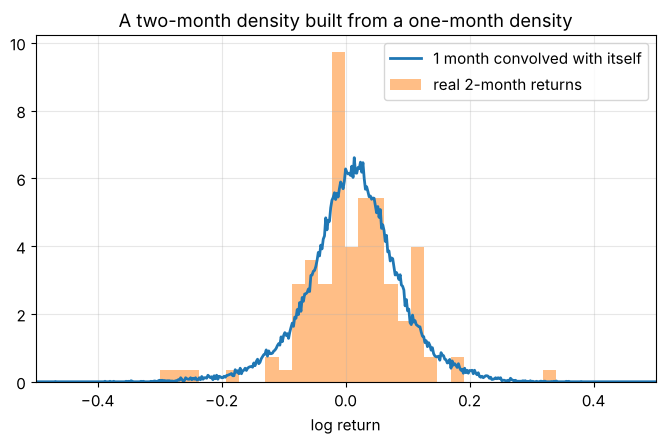

In [5]:
# monthly log returns of the IPC (non-overlapping), and 2-month returns from the same history
lp = np.log(prices["IPC"].dropna().values)
m1 = lp[21::21] - lp[:-21:21]
m2 = lp[42::42] - lp[:-42:42]

# density of one month on a fine grid, then convolve it with itself: the density of a sum of two months
step = 0.002
grid = np.arange(-0.6, 0.6 + step, step)
f, _ = np.histogram(m1, bins=np.append(grid - step / 2, grid[-1] + step / 2), density=True)
f2 = np.convolve(f, f) * step
grid2 = np.arange(len(f2)) * step + 2 * grid[0]

def quantile_from_density(dens, g, q):
    cdf = np.cumsum(dens) * step
    return g[np.searchsorted(cdf, q)]

print(f"{'':<26}{'std':>8}{'5% worst':>10}")
print(f"{'convolution of 1 month':<26}{sqrt(np.sum(f2 * grid2**2) * step - (np.sum(f2 * grid2) * step)**2):>8.2%}{-quantile_from_density(f2, grid2, 0.05):>10.2%}")
print(f"{'real 2-month returns':<26}{m2.std():>8.2%}{-np.quantile(m2, 0.05):>10.2%}")
print(f"{'1 month x sqrt(2)':<26}{m1.std() * sqrt(2):>8.2%}")
print(f"\nmonths used: {len(m1)}   two-month periods: {len(m2)}")

# how noisy is the real 2-month std? bootstrap the 130 periods, and start the periods one month later
rng = np.random.default_rng(37)
boot = [np.std(rng.choice(m2, len(m2)), ddof=1) for _ in range(5000)]
m2_shift = lp[21:][42::42] - lp[21:][:-42:42]
print(f"standard error of the real 2-month std (bootstrap): {np.std(boot):.2%}")
print(f"real 2-month std if the periods start one month later: {m2_shift.std():.2%}")

plt.plot(grid2, f2, lw=2, label="1 month convolved with itself")
plt.hist(m2, bins=30, density=True, alpha=0.5, label="real 2-month returns")
plt.xlim(-0.5, 0.5); plt.title("A two-month density built from a one-month density")
plt.xlabel("log return"); plt.legend(); plt.show()

The convolution gives a standard deviation of 7.52%, exactly one month times $\sqrt{2}$, and the real
two-month returns have 8.23%. That gap looks like memory between consecutive months, but it is not
clear. The standard error of the real number is 0.86%, larger than the gap, and if the two-month
periods start one month later the real standard deviation is 6.46%, now below the convolution. The 5%
worst case also goes the other way (11.2% against 9.6%). With only 130 two-month periods the real
numbers move this much just by noise, so the data cannot tell the convolution apart from what
happened, and treating the months as independent works well.

## 5. From Black-Scholes to the diffusion equation

With the change of variables $x = \ln S$ and $\tau = T - t$ (time to expiry), the Black-Scholes equation
becomes

$$\frac{\partial V}{\partial \tau} = \frac12\sigma^2 \frac{\partial^2 V}{\partial x^2} +
\left(r - \tfrac12\sigma^2\right)\frac{\partial V}{\partial x} - rV,$$

which is a diffusion equation with a drift and a discount term. The payoff at expiry becomes the
starting condition, and the equation is solved forward in $\tau$.

**Exercise 5. Solving the equation for a real SPY call.** I solve this equation with a simple
finite-difference scheme for a one-month at-the-money SPY call with today's inputs (SPY price, VIX and
US 3-month rate), and compare with the Black-Scholes formula.

In [6]:
# solve the Black-Scholes PDE in x = ln S, time to expiry tau, with an explicit finite-difference scheme:
# dV/dtau = 1/2 sigma^2 V_xx + (r - sigma^2/2) V_x - r V
K = S0
x = np.linspace(log(S0) - 1.0, log(S0) + 1.0, 401)
dx = x[1] - x[0]
dtau = 0.4 * dx**2 / sig0**2                       # small enough for the explicit scheme to be stable
n_steps = int(np.ceil(T0 / dtau)); dtau = T0 / n_steps
V = np.maximum(np.exp(x) - K, 0)                    # payoff at expiry = initial condition
for _ in range(n_steps):
    Vxx = (V[2:] - 2 * V[1:-1] + V[:-2]) / dx**2
    Vx = (V[2:] - V[:-2]) / (2 * dx)
    V[1:-1] += dtau * (0.5 * sig0**2 * Vxx + (r0 - 0.5 * sig0**2) * Vx - r0 * V[1:-1])
    V[0], V[-1] = 0, np.exp(x[-1]) - K * exp(-r0 * T0)

pde_price = np.interp(log(S0), x, V)
print(f"{n_steps} time steps on a grid of {len(x)} points")
print(f"PDE solution : {pde_price:.4f}")
print(f"BS formula   : {bs_call(S0, K, T0, r0, sig0)[0]:.4f}")

238 time steps on a grid of 401 points
PDE solution : 16.2592
BS formula   : 16.2709


The numerical solution gives 16.2592 and the formula 16.2709, a difference of about 0.07%, which comes
from the size of the grid. So the formula is exactly what the equation gives when it is solved, and a
computer can solve it step by step for any payoff where there is no formula.

## 6. Recovering the Black-Scholes price from the kernel

Combining the last sections, the price is the payoff averaged over the Gaussian kernel and discounted:

$$V = e^{-r\tau}\int \max\!\left(S\,e^{(r-\frac12\sigma^2)\tau + \sigma\sqrt{\tau}\,z} - K,\ 0\right)\varphi(z)\,dz.$$

Doing this integral by hand gives $S\Phi(d_1) - Ke^{-r\tau}\Phi(d_2)$.

**Exercise 6. The integral against the formula.** For today's SPY, I compute the integral numerically
for five strikes, from 90% to 110% of the current price.

In [7]:
# price as a discounted average of the payoff over the normal kernel, integrated numerically
z = np.linspace(-8, 8, 4001)
w = np.exp(-z**2 / 2) / sqrt(2 * pi)
ST = S0 * np.exp((r0 - sig0**2 / 2) * T0 + sig0 * sqrt(T0) * z)

print(f"{'strike':>8}{'% of spot':>11}{'kernel integral':>17}{'BS formula':>12}")
for k in [0.90, 0.95, 1.00, 1.05, 1.10]:
    K = k * S0
    integral = exp(-r0 * T0) * np.trapezoid(np.maximum(ST - K, 0) * w, z)
    print(f"{K:>8.2f}{k:>11.0%}{integral:>17.4f}{bs_call(S0, K, T0, r0, sig0)[0]:>12.4f}")

  strike  % of spot  kernel integral  BS formula
  692.64        90%          79.4743     79.4743
  731.12        95%          43.3567     43.3567
  769.60       100%          16.2709     16.2709
  808.08       105%           3.6300      3.6300
  846.56       110%           0.4484      0.4484


The integral and the formula agree to four decimals for every strike, from 79.47 dollars for the
deepest in-the-money call to 0.45 for the furthest out of the money. So the formula is just the average
payoff over a normal distribution, discounted at the risk-free rate.

## 7. Fixed income: why bonds are harder

For a bond, the variable that drives the price is the short interest rate $r$, and $r$ cannot be bought
or sold, so it cannot be used to hedge. A popular model for $r$ is **Vasicek**, which is the
Ornstein-Uhlenbeck process of Module 4:

$$dr = \alpha(\bar y - r)\,dt + \sigma\,dB.$$

Its zero-coupon bond prices have a closed form, $P(\tau) = A(\tau)e^{-B(\tau)r}$, and the yield for
very long maturities tends to $\bar y - \sigma^2/(2\alpha^2)$.

**Exercise 7. Vasicek against today's US curve.** I fit Vasicek to the monthly US 3-month rate since
2005, as in Module 4, and use it to compute the yields of 1, 2, 5 and 10 years for today's rate.

In [8]:
# US Treasury curve at the end of each month, in decimals
cols = ["US3M", "US1Y", "US2Y", "US5Y", "US10Y"]
taus = np.array([0.25, 1, 2, 5, 10])
curve = rates[cols].dropna().resample("ME").last().dropna() / 100

# Vasicek dr = alpha (ybar - r) dt + sigma dB, fitted to the monthly 3-month rate as an AR(1) (as in Module 4)
y, z = curve["US3M"].values[1:], curve["US3M"].values[:-1]
b = np.sum((z - z.mean()) * (y - y.mean())) / np.sum((z - z.mean())**2)
a = y.mean() - b * z.mean()
alpha, ybar = -log(b) * 12, a / (1 - b)
sigma = np.std(y - a - b * z) * sqrt(2 * alpha / (1 - b**2))

def vasicek_yield(r, tau, alpha, ybar, sigma):
    # zero-coupon yield of the Vasicek model, written by hand
    B = (1 - np.exp(-alpha * tau)) / alpha
    lnA = (B - tau) * (ybar - sigma**2 / (2 * alpha**2)) - sigma**2 * B**2 / (4 * alpha)
    return -(lnA - B * r) / tau

print(f"Vasicek fitted to the 3-month rate: alpha = {alpha:.3f}   ybar = {ybar:.2%}   sigma = {sigma:.2%}")
print(f"long-maturity yield of the model: ybar - sigma^2 / (2 alpha^2) = {ybar - sigma**2 / (2 * alpha**2):.2%}\n")

today = curve.iloc[-1]
model = vasicek_yield(today["US3M"], taus, alpha, ybar, sigma)
print(f"{'maturity':>9}{'real yield':>12}{'Vasicek':>10}")
for t, c, mv in zip(taus, cols, model):
    print(f"{t:>8}y{today[c]:>12.2%}{mv:>10.2%}")

Vasicek fitted to the 3-month rate: alpha = 0.037   ybar = 3.80%   sigma = 0.70%
long-maturity yield of the model: ybar - sigma^2 / (2 alpha^2) = 1.98%

 maturity  real yield   Vasicek
    0.25y       4.09%     4.09%
     1.0y       4.48%     4.08%
     2.0y       4.79%     4.08%
     5.0y       5.00%     4.05%
    10.0y       5.21%     3.98%


The model fails badly. Today the real curve goes up, from 4.09% at 3 months to 5.21% at 10 years, but
the model gives a curve that goes down, to 3.98% at 10 years, and its long-maturity yield is only
1.98%. The reason is that the model only knows the history of the short rate, which spent years near
zero, and it says nothing about what investors ask for holding long bonds. That missing piece is the
market price of risk. There is also a second problem: $\alpha = 0.037$ is the same estimate as in
Module 4, where the half-life of the rate could be anything from 3.5 years to infinite, and the
long-maturity yield depends a lot on $\alpha$. So the exact numbers of the model are very uncertain,
even if the wrong slope is clear.

## 8. The market price of risk

Since the rate cannot be traded, the bond price depends on an extra number, the **market price of
risk** $\eta$: the additional return that investors ask per unit of risk. It is the same for every bond,
and in Vasicek it works as if the long-run mean were higher, $\bar y^* = \bar y + \eta\sigma/\alpha$.
It cannot be estimated from the short rate, but it can be read from the bond prices.

**Exercise 8. Reading $\eta$ from the curve.** For every month since 2005 I keep $\alpha$ and $\sigma$
fixed and choose $\bar y^*$ so that the model matches the 1, 2, 5 and 10-year yields as well as
possible, with least squares written by hand. Then I convert it into $\eta$.

market price of risk eta: average 0.32   range -0.54 to 1.13
average fit error of the curve: 0.20%
average 10-year minus 3-month spread in the data: 1.23%


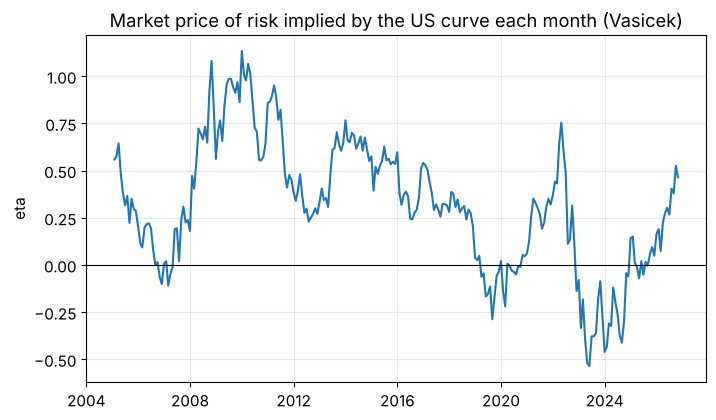

In [9]:
# with a market price of risk eta, bonds are priced with a higher long-run mean: ybar* = ybar + eta sigma / alpha.
# The model yield is linear in ybar*, so ybar* can be fitted to each month's curve by least squares, by hand.
def fit_ybar_star(r, obs):
    B = (1 - np.exp(-alpha * taus[1:])) / alpha
    t = taus[1:]
    base = (-(B - t) * (-sigma**2 / (2 * alpha**2)) + sigma**2 * B**2 / (4 * alpha) + B * r) / t
    slope = -(B - t) / t                              # yield = base + slope * ybar*
    ys = np.sum(slope * (obs - base)) / np.sum(slope**2)
    return ys, base + slope * ys

rows = []
for d, row in curve.iterrows():
    ys, fit = fit_ybar_star(row["US3M"], row[cols[1:]].values)
    rows.append([d, ys, (ys - ybar) * alpha / sigma, np.sqrt(np.mean((fit - row[cols[1:]].values)**2))])
mpr = pd.DataFrame(rows, columns=["date", "ybar*", "eta", "fit error"]).set_index("date")

print(f"market price of risk eta: average {mpr['eta'].mean():.2f}   range {mpr['eta'].min():.2f} to {mpr['eta'].max():.2f}")
print(f"average fit error of the curve: {mpr['fit error'].mean():.2%}")
print(f"average 10-year minus 3-month spread in the data: {(curve['US10Y'] - curve['US3M']).mean():.2%}")

plt.plot(mpr.index, mpr["eta"], lw=1.5)
plt.axhline(0, color="black", lw=0.8)
plt.title("Market price of risk implied by the US curve each month (Vasicek)")
plt.ylabel("eta"); plt.show()

With one extra number per month, the model now fits the real curve with an average error of only
0.20%. The market price of risk was positive on average (0.32), which means that investors usually ask
for more return on long bonds. This is consistent with the 10-year yield being on average 1.23% above
the 3-month rate. But $\eta$ is not constant: it went from $-0.54$ to $1.13$. A model that needs a different
"constant" every month is describing the curve more than explaining it, and this is a real limit of
one-factor models.

## 9. What yield curves can this model produce?

A one-factor model can produce curves that go up, curves that go down (inverted), and in some cases a
hump, but all the movement comes from one random variable. Real curves can change their level, their
slope and their curvature separately.

**Exercise 9. Real shapes against model shapes.** I classify every monthly US curve as upward,
inverted or humped, compare it with the shape of the fitted Vasicek curve, and look at the fit error by
shape. I also compare the short and long rates of Mexico.

          real share  model share  fit error (%)
humped         0.053        0.000          0.249
inverted       0.137        0.195          0.244
upward         0.809        0.805          0.184

humped months: 14, of which the model calls 9 inverted and 5 upward

Mexico: 197 months, 10-year below 3-month in 34% of them
share of months with the 10-year below the 3-month, by year:
  2005: 67%  2006: 8%  2007: 45%  2008: 67%  2009: 0%  2010: 0%  2011: 0%  2012: 0%  2013: 0%  2014: 0%  2015: 0%  2016: 0%  2017: 56%  2018: 75%  2019: 89%  2020: 22%  2021: 0%  2022: 40%  2023: 100%  2024: 100%  2025: 27%  2026: 0%


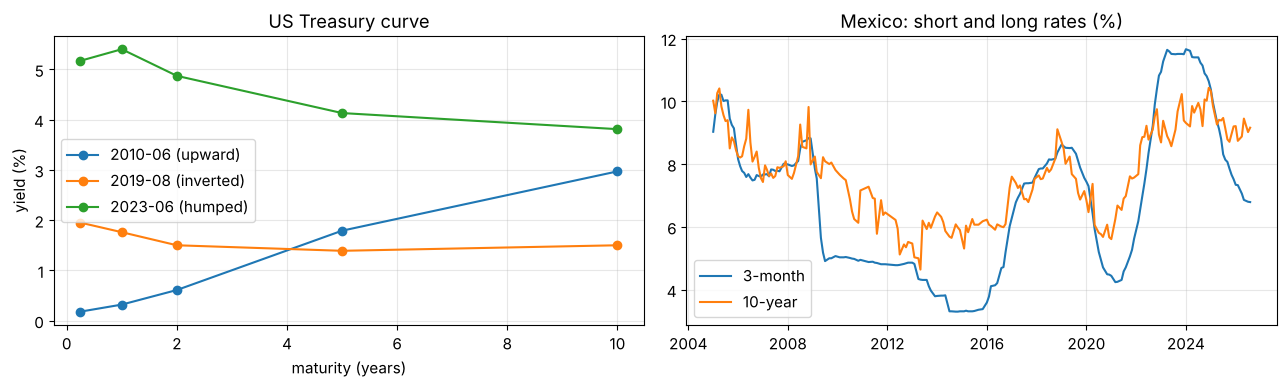

In [10]:
def shape(v):
    # v = yields from short to long
    if np.argmax(v) not in (0, len(v) - 1) and v.max() > max(v[0], v[-1]) + 0.001:
        return "humped"
    return "upward" if v[-1] > v[0] else "inverted"

real_shape = curve[cols].apply(lambda r: shape(r.values), axis=1)
fit_shape = []
for d, row in curve.iterrows():
    ys = mpr.loc[d, "ybar*"]
    fit_shape.append(shape(vasicek_yield(row["US3M"], taus, alpha, ys, sigma)))
fit_shape = pd.Series(fit_shape, index=curve.index)

tab = pd.DataFrame({"real share": real_shape.value_counts(normalize=True),
                    "model share": fit_shape.value_counts(normalize=True)}).fillna(0)
tab["fit error (%)"] = mpr.groupby(real_shape)["fit error"].mean() * 100
print(tab.round(3).to_string())
hump = real_shape == "humped"
print(f"\nhumped months: {hump.sum()}, of which the model calls {np.sum(fit_shape[hump] == 'inverted')} inverted "
      f"and {np.sum(fit_shape[hump] == 'upward')} upward")

# Mexico: 3-month vs 10-year, monthly
mx = rates[["MX3M", "MX10Y"]].dropna()
print(f"\nMexico: {len(mx)} months, 10-year below 3-month in {np.mean(mx['MX10Y'] < mx['MX3M']):.0%} of them")
by_year = (mx["MX10Y"] < mx["MX3M"]).groupby(mx.index.year).mean()
print("share of months with the 10-year below the 3-month, by year:")
print("  " + "  ".join(f"{y}: {v:.0%}" for y, v in by_year.items()))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for d in ["2010-06", "2019-08", "2023-06"]:
    row = curve.loc[d].iloc[0]
    ax[0].plot(taus, row[cols].values * 100, "o-", label=f"{d} ({real_shape.loc[d].iloc[0]})")
ax[0].set_xlabel("maturity (years)"); ax[0].set_ylabel("yield (%)"); ax[0].set_title("US Treasury curve"); ax[0].legend()
ax[1].plot(mx.index, mx["MX3M"], label="3-month"); ax[1].plot(mx.index, mx["MX10Y"], label="10-year")
ax[1].set_title("Mexico: short and long rates (%)"); ax[1].legend()
plt.tight_layout(); plt.show()

In the US, 81% of the months had an upward curve, 14% an inverted curve and 5% a humped one. The
fitted model gets the upward share right, but it never produces a hump: 9 of the 14 humped months
come out as inverted, and its error is larger for humped and inverted curves (0.24% to 0.25%) than for
upward curves (0.18%). Mexico shows why this matters for a Mexican investor: the 10-year rate was below the
3-month rate in 34% of the months, much more often than in the US. The inversions come in blocks: two
thirds of the months in 2005 and 2008, 75% in 2018, 89% in 2019 and all of 2023 and 2024, and none from
2009 to 2016. These blocks match the periods when Banxico kept the short rate high while the long rate
moved less. A single-factor model
has a hard time with these periods, because the short and the long end move for different reasons. The
comparison is approximate, because the Mexican 3-month rate is an interbank rate and the 10-year is a
government bond, and both are monthly.

## Wrapping up Module 5

This module solved Black-Scholes properly and then tried the same tools on bonds. With real data,
delta moves a lot inside a month, so the self-financing condition is necessary, and a self-financing
hedge has half the risk of a static one. Solving the equation numerically and integrating the payoff
over the Gaussian kernel both give the Black-Scholes formula with today's SPY inputs, so the formula is
exactly an average payoff.

Bonds are a different story. Vasicek fitted only to the short rate gives a curve that goes the wrong
way, and it needs a market price of risk that changes every month to match the real US curve. Even
then, it cannot produce humps, and the frequent inversions in Mexico show that short and long rates
often move for different reasons. One random factor is enough to explain the idea of bond pricing, but
not to describe a real curve.

The next step is Module 6, which looks at all the paths at once, adds barriers, and uses the solution
to measure risk.